# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


**Dataset yang dipakai: Influencer Marketing ROI Dataset**

| Keterangan | Isi |
|---|---|
| Sumber | Kaggle, pengguna `tfisthis` |
| Tautan | https://www.kaggle.com/datasets/tfisthis/influencer-marketing-roi-dataset |
| Lisensi | **[ISI SENDIRI: lihat bagian License di halaman Kaggle]** |
| Jumlah data | 150.000 baris, 10 kolom |
| Format | CSV (data terstruktur/tabular) |

**Deskripsi kolom** (berdasarkan nama kolom dan hasil pemeriksaan data):

| Kolom | Tipe | Keterangan |
|---|---|---|
| `campaign_id` | teks | Pengenal unik kampanye |
| `platform` | kategorikal | Platform media sosial (Instagram, YouTube, TikTok, Twitter) |
| `influencer_category` | kategorikal | Niche influencer (7 kategori) |
| `campaign_type` | kategorikal | Jenis kampanye (5 jenis) |
| `start_date`, `end_date` | tanggal | Tanggal mulai dan selesai kampanye |
| `campaign_duration_days` | numerik | Durasi kampanye dalam hari |
| `estimated_reach` | numerik | Perkiraan jumlah orang yang terjangkau |
| `engagements` | numerik | Jumlah interaksi (**target prediksi**) |
| `product_sales` | numerik | Penjualan produk (hasil kampanye) |

**Definisi masalah.** Memprediksi `engagements` (regresi) dari informasi yang sudah diketahui saat kampanye
direncanakan: `platform`, `influencer_category`, `campaign_type`, `estimated_reach`, dan `campaign_duration_days`.

Kolom `product_sales` **tidak dipakai sebagai fitur** karena baru diketahui setelah kampanye berjalan. `campaign_id`
hanya pengenal, dan kolom tanggal (`start_date`, `end_date`) tidak dipakai karena ternyata berisi urutan hari
berturut-turut, bukan tanggal kampanye nyata (lihat bagian 4.7).

**Catatan penting.** Dari pemeriksaan awal, kolom numerik tampak tersebar merata dan saling bebas, sehingga
dataset ini diduga data simulasi. Tujuan proyek ini adalah membangun alur machine learning yang lengkap
(preprocessing, pelatihan, pelacakan, CI, dan monitoring), bukan mengejar akurasi yang tinggi.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
# Library standar
import warnings
from datetime import date
from pathlib import Path

# Data dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistik dan preprocessing
import joblib
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42   # supaya hasil pembagian data selalu sama


def ke_ordinal(teks):
    # Mengubah teks tanggal menjadi nomor hari (bilangan bulat).
    # Memakai modul datetime bawaan Python, bukan pd.to_datetime, karena pandas hanya mendukung
    # tahun 1677 sampai 2262. Tanggal di luar rentang itu akan diam-diam menjadi NaT.
    # Teks yang bukan tanggal valid menghasilkan NaN.
    try:
        return date.fromisoformat(str(teks)[:10]).toordinal()
    except ValueError:
        return np.nan

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
# Lokasi data mentah relatif terhadap folder notebook ini (preprocessing/)
RAW_PATH = Path("../influencer_marketing_roi_raw/influencer_marketing_roi_dataset.csv")

if RAW_PATH.exists():
    df = pd.read_csv(RAW_PATH)
    print("Sumber data :", RAW_PATH.resolve())
else:
    # Cadangan (misalnya di Colab tanpa repo): unduh langsung dari Kaggle.
    # Jika muncul ModuleNotFoundError, jalankan dulu: %pip install kagglehub
    import kagglehub
    folder = Path(kagglehub.dataset_download("tfisthis/influencer-marketing-roi-dataset"))
    df = pd.read_csv(next(folder.glob("*.csv")))
    print("Sumber data : Kaggle (kagglehub) ->", folder)

print("Shape       :", df.shape)
df.head()

Sumber data : C:\Users\user\Project AI\AI Campaign Influencer\msml-workspace\Eksperimen_SML_Kalyca-Venezia\influencer_marketing_roi_raw\influencer_marketing_roi_dataset.csv
Shape       : (150000, 10)


,campaign_id,platform,influencer_category,campaign_type,start_date,engagements,estimated_reach,product_sales,campaign_duration_days,end_date
0,CAMP100000,TikTok,Fitness,Giveaway,2022-01-01 00:00:00,79900,1892,2834,14,2022-01-15 00:00:00
1,CAMP100001,YouTube,Food,Product Launch,2022-01-02 00:00:00,47985,437228,165,13,2022-01-15 00:00:00
2,CAMP100002,TikTok,Travel,Brand Awareness,2022-01-03 00:00:00,13875,982513,2539,5,2022-01-08 00:00:00
3,CAMP100003,YouTube,Food,Brand Awareness,2022-01-04 00:00:00,41200,213400,100,20,2022-01-24 00:00:00
4,CAMP100004,Instagram,Food,Giveaway,2022-01-05 00:00:00,96998,42501,550,28,2022-02-02 00:00:00


In [3]:
# Pastikan semua kolom yang dibutuhkan ada
KOLOM_WAJIB = {
    "campaign_id", "platform", "influencer_category", "campaign_type", "start_date",
    "engagements", "estimated_reach", "product_sales", "campaign_duration_days", "end_date",
}
assert KOLOM_WAJIB <= set(df.columns), f"Kolom hilang: {KOLOM_WAJIB - set(df.columns)}"

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   campaign_id             150000 non-null  object
 1   platform                150000 non-null  object
 2   influencer_category     150000 non-null  object
 3   campaign_type           150000 non-null  object
 4   start_date              150000 non-null  object
 5   engagements             150000 non-null  int64 
 6   estimated_reach         150000 non-null  int64 
 7   product_sales           150000 non-null  int64 
 8   campaign_duration_days  150000 non-null  int64 
 9   end_date                150000 non-null  object
dtypes: int64(4), object(6)
memory usage: 11.4+ MB


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

## 4.1 Statistik deskriptif
Melihat ringkasan angka tiap kolom numerik: rentang nilai, rata-rata, dan sebaran kuartil.

In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
engagements,150000.0,50065.296107,28847.302798,100.0,25060.5,50100.5,75045.25,99999.0
estimated_reach,150000.0,500239.634920,288003.388219,1002.0,251439.5,500073.5,750016.75,999992.0
product_sales,150000.0,2497.730433,1443.222587,0.0,1248.0,2501.0,3746.00,4999.0
campaign_duration_days,150000.0,14.976127,8.358356,1.0,8.0,15.0,22.00,29.0


## 4.2 Kualitas data
Memeriksa nilai kosong, baris duplikat, dan keunikan `campaign_id`.

In [5]:
print("Missing value per kolom:")
print(df.isnull().sum())
print()
print("Total missing   :", int(df.isnull().sum().sum()))
print("Baris duplikat  :", int(df.duplicated().sum()))
print("campaign_id unik:", df["campaign_id"].is_unique,
      "| id yang terduplikasi:", int(df["campaign_id"].duplicated().sum()))

Missing value per kolom:
campaign_id               0
platform                  0
influencer_category       0
campaign_type             0
start_date                0
engagements               0
estimated_reach           0
product_sales             0
campaign_duration_days    0
end_date                  0
dtype: int64

Total missing   : 0
Baris duplikat  : 0
campaign_id unik: True | id yang terduplikasi: 0


## 4.3 Kolom kategorikal
Melihat nilai apa saja yang ada dan seberapa seimbang jumlahnya.

platform -> 4 nilai unik
influencer_category -> 7 nilai unik
campaign_type -> 5 nilai unik


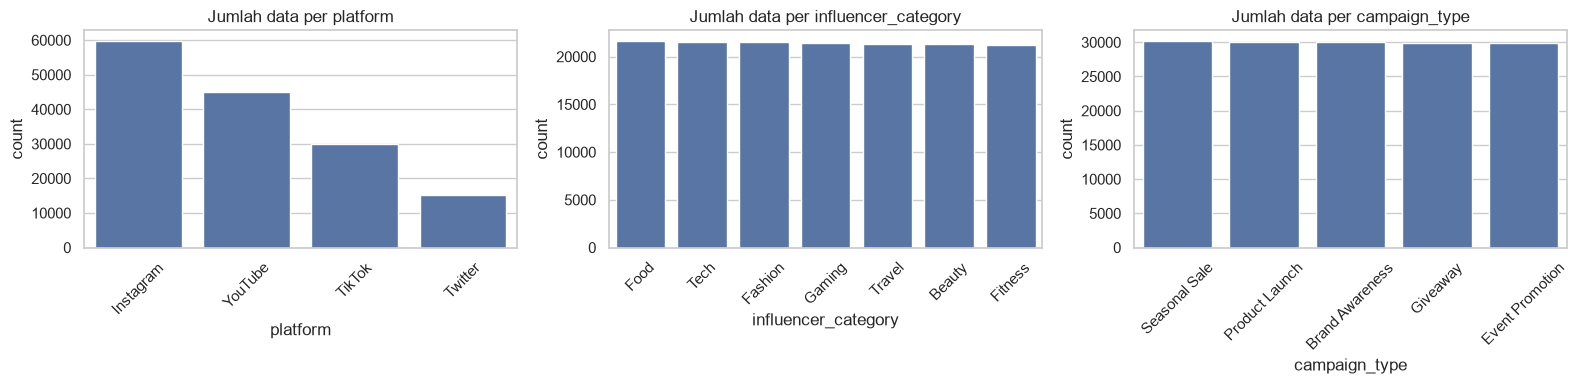

In [6]:
KOLOM_KATEGORI = ["platform", "influencer_category", "campaign_type"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, kol in zip(axes, KOLOM_KATEGORI):
    urutan = df[kol].value_counts().index
    sns.countplot(data=df, x=kol, order=urutan, ax=ax)
    ax.set_title(f"Jumlah data per {kol}")
    ax.tick_params(axis="x", rotation=45)
    print(kol, "->", df[kol].nunique(), "nilai unik")
plt.tight_layout()
plt.show()

## 4.4 Distribusi kolom numerik
Histogram dan nilai *skewness* (kemiringan). Skewness mendekati 0 berarti distribusi simetris.

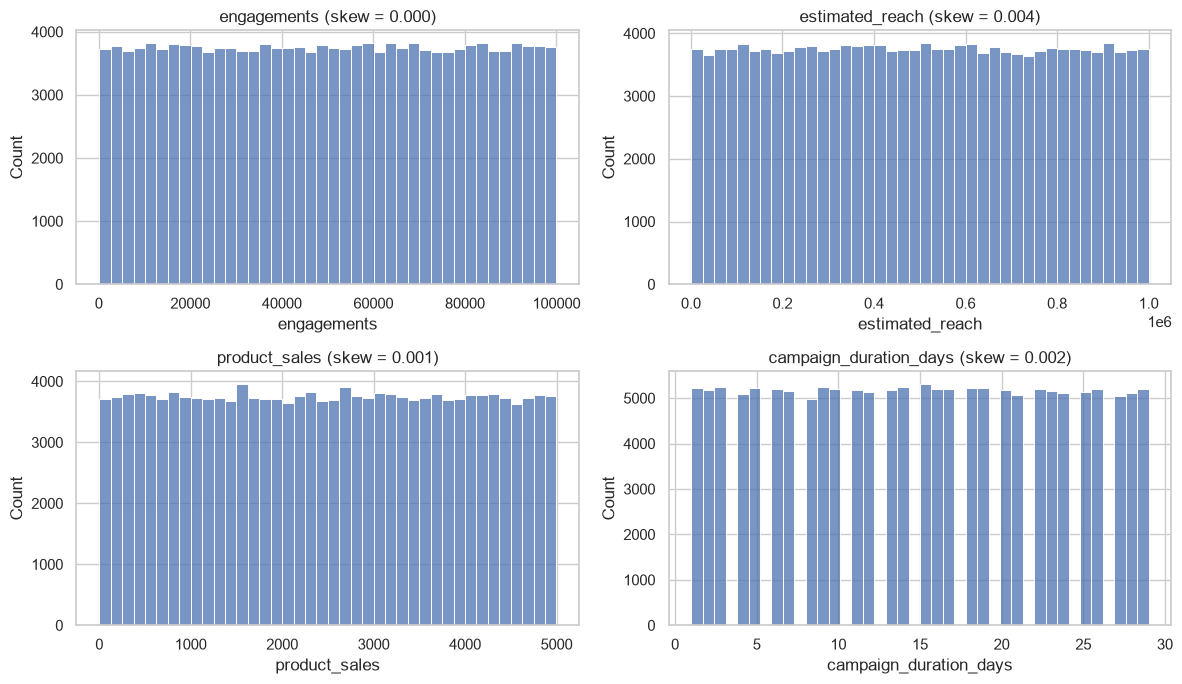

In [7]:
KOLOM_NUMERIK_EDA = ["engagements", "estimated_reach", "product_sales", "campaign_duration_days"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, kol in zip(axes.ravel(), KOLOM_NUMERIK_EDA):
    sns.histplot(df[kol], bins=40, ax=ax)
    ax.set_title(f"{kol} (skew = {df[kol].skew():.3f})")
plt.tight_layout()
plt.show()

## 4.5 Korelasi antar kolom numerik
Korelasi Pearson berkisar -1 sampai 1. Nilai mendekati 0 berarti tidak ada hubungan linear.

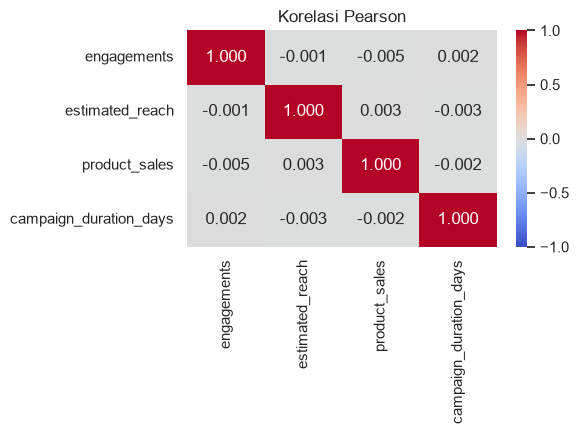

In [8]:
korelasi = df[KOLOM_NUMERIK_EDA].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(korelasi, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Pearson")
plt.tight_layout()
plt.show()

## 4.6 Target (`engagements`) menurut kategori
Boxplot memakai sampel 20.000 baris agar cepat. Uji Kruskal-Wallis dihitung dari **seluruh** data:
jika p-value di atas 0,05, tidak ada bukti bahwa engagements berbeda antar kelompok.

Pada data sebesar ini (150.000 baris), perbedaan yang sangat kecil pun bisa menghasilkan p-value rendah. Karena itu
dilihat juga **ukuran efek**: nilai 0,001 berarti kategori hanya menjelaskan sekitar 0,1% variasi engagements.

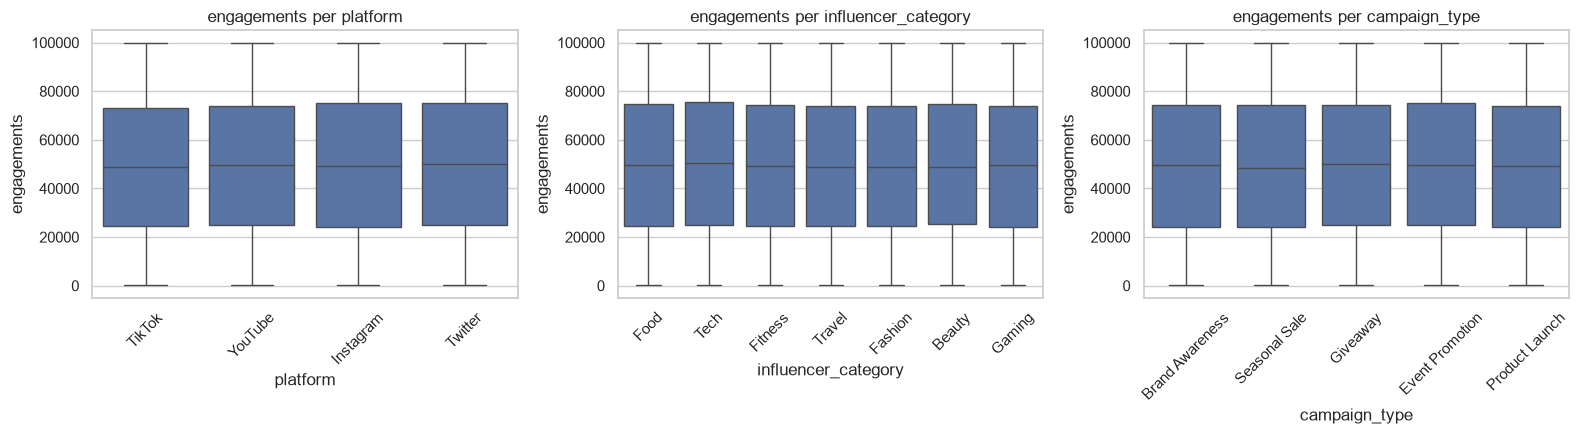

Uji Kruskal-Wallis (seluruh data):
  platform               H =     3.93   p-value = 0.2694   ukuran efek = 0.00003
  influencer_category    H =     5.84   p-value = 0.4413   ukuran efek = 0.00004
  campaign_type          H =    14.76   p-value = 0.0052   ukuran efek = 0.00010

Rata-rata engagements per jenis kampanye:
campaign_type
Product Launch     49730.0
Event Promotion    49853.0
Brand Awareness    50021.0
Seasonal Sale      50164.0
Giveaway           50556.0


In [9]:
sampel = df.sample(20000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kol in zip(axes, KOLOM_KATEGORI):
    sns.boxplot(data=sampel, x=kol, y="engagements", ax=ax)
    ax.set_title(f"engagements per {kol}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Uji Kruskal-Wallis (seluruh data):")
n_data = len(df)
for kol in KOLOM_KATEGORI:
    kelompok = [g["engagements"].values for _, g in df.groupby(kol)]
    h, p = stats.kruskal(*kelompok)
    efek = h / (n_data - 1)   # epsilon kuadrat: kira-kira proporsi variasi yang dijelaskan kategori
    print(f"  {kol:<22} H = {h:8.2f}   p-value = {p:.4f}   ukuran efek = {efek:.5f}")

print("\nRata-rata engagements per jenis kampanye:")
print(df.groupby("campaign_type")["engagements"].mean().round(0).sort_values().to_string())

## 4.7 Analisis tanggal
Tanggal diperiksa memakai `ke_ordinal` (modul `datetime` Python), bukan `pd.to_datetime`, karena pandas hanya
mendukung tahun sampai 2262 dan akan mengubah tanggal yang lebih jauh menjadi `NaT` tanpa peringatan.
Kita periksa rentangnya, keunikannya, dan apakah tanggal benar-benar mencerminkan waktu kampanye.

Tanggal tak terbaca (teks bukan tanggal) : 0
Rentang tahun start_date                 : 2022 sampai 2432
Baris dengan start_date setelah 2262-04-11: 62241 (di luar batas pandas)
Jumlah tanggal start_date yang unik      : 150000 dari 150000 baris
start_date urut menaik mengikuti baris   : True

Selisih hari antara baris yang berurutan:
mulai
1.0    149999
Name: count, dtype: int64


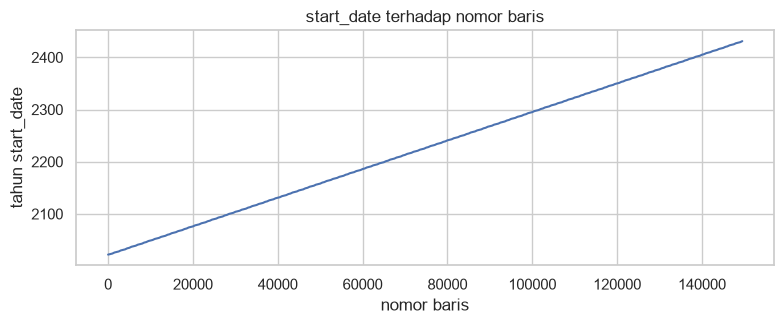

In [10]:
tgl = df[["start_date", "end_date"]].copy()
tgl["mulai"] = tgl["start_date"].map(ke_ordinal)
tgl["selesai"] = tgl["end_date"].map(ke_ordinal)

tahun = pd.to_numeric(tgl["start_date"].astype(str).str.slice(0, 4), errors="coerce")
BATAS_PANDAS = date(2262, 4, 11).toordinal()   # tanggal terakhir yang bisa dibaca pd.to_datetime

print("Tanggal tak terbaca (teks bukan tanggal) :", int(tgl[["mulai", "selesai"]].isna().any(axis=1).sum()))
print("Rentang tahun start_date                 :", int(tahun.min()), "sampai", int(tahun.max()))
print("Baris dengan start_date setelah 2262-04-11:", int((tgl["mulai"] > BATAS_PANDAS).sum()), "(di luar batas pandas)")
print("Jumlah tanggal start_date yang unik      :", tgl["mulai"].nunique(), "dari", len(tgl), "baris")
print("start_date urut menaik mengikuti baris   :", tgl["mulai"].is_monotonic_increasing)
print("\nSelisih hari antara baris yang berurutan:")
print(tgl["mulai"].diff().dropna().value_counts().head())

plt.figure(figsize=(8, 3.4))
plt.plot(df.index[::500], tahun.iloc[::500])
plt.xlabel("nomor baris")
plt.ylabel("tahun start_date")
plt.title("start_date terhadap nomor baris")
plt.tight_layout()
plt.show()

## 4.8 Pemeriksaan konsistensi data
Dua hal yang tampak janggal dan perlu dicek: (1) engagements lebih besar dari estimated_reach, dan
(2) apakah durasi sesuai dengan selisih tanggal.

In [11]:
n_lebih = int((df["engagements"] > df["estimated_reach"]).sum())
print(f"Baris dengan engagements > estimated_reach: {n_lebih} ({n_lebih / len(df):.2%})")

selisih = tgl["selesai"] - tgl["mulai"] - df["campaign_duration_days"]
print("\nSelisih antara (end_date - start_date) dan campaign_duration_days:")
print(selisih.value_counts(dropna=False).head(10))
print("\nBaris dengan end_date < start_date:", int((tgl["selesai"] < tgl["mulai"]).sum()))

Baris dengan engagements > estimated_reach: 7391 (4.93%)

Selisih antara (end_date - start_date) dan campaign_duration_days:
0    150000
Name: count, dtype: int64

Baris dengan end_date < start_date: 0


## 4.9 Kesimpulan EDA

**Temuan yang sudah terkonfirmasi dari pemeriksaan data:**
- Data lengkap: tidak ada missing value dan tidak ada baris duplikat.
- `engagements` tersebar merata antara 100 dan 99.999 dengan skewness mendekati 0, sehingga **tidak perlu transformasi log**.
- Korelasi `engagements` dengan `estimated_reach` hanya sekitar -0,001: hampir tidak ada hubungan linear.
- Sekitar 4,9% baris (7.391 dari 150.000) memiliki engagements lebih besar dari estimated_reach. Angka ini sangat dekat
  dengan perkiraan teoretis 5% jika kedua kolom diacak seragam dan saling bebas, sehingga lebih mungkin merupakan
  efek data simulasi daripada kesalahan pencatatan.
- Uji awal dengan model boosting tidak mengungguli baseline rata-rata (R2 mendekati 0).
- `start_date` bukan tanggal kampanye nyata: nilainya bertambah tepat satu hari per baris, dimulai 2022-01-01 dan
  berakhir di tahun 2432 (satu kampanye per hari selama sekitar 411 tahun). Sebagian tanggal juga melewati batas
  tahun 2262 yang bisa dibaca pandas. Karena itu kolom tanggal **tidak dipakai sebagai fitur** dan **tidak ada baris
  yang dibuang** hanya karena tanggalnya.

**Temuan tambahan (ISI SENDIRI setelah melihat output di atas, ganti teks ini):**
- Hasil uji Kruskal-Wallis: kolom mana yang p-value-nya di bawah 0,05, dan seberapa besar ukuran efeknya? Apakah
  perbedaan itu cukup berarti secara praktis?
- Selisih durasi terhadap tanggal: apakah selalu 0, atau ada selisih lain?
- Hal lain yang kamu temukan dari grafik dan angka di atas.

**Implikasi untuk preprocessing:** semua baris dipertahankan (termasuk baris engagements > estimated_reach, lihat
alasan di bagian 5.6), kolom tanggal tidak dipakai, kolom kategorikal di-*one-hot*, dan fitur numerik distandarisasi.

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

## 5.1 Salin data mentah
Semua langkah bekerja pada salinan agar data mentah (`df`) tetap utuh.

In [12]:
data = df.copy()
print("Baris awal:", len(data))

Baris awal: 150000


## 5.2 Menangani missing value
Dari EDA tidak ada nilai kosong. Langkah ini tetap dijalankan **lebih dulu** sebagai pengaman: jika ada, barisnya
dibuang. Urutannya penting, karena mengubah kolom kosong menjadi teks (misalnya `"nan"`) sebelum langkah ini akan
membuat nilai kosong lolos tanpa terdeteksi.

In [13]:
kosong = data.isnull().sum()
kosong = kosong[kosong > 0]
print("Kolom yang punya missing value:")
print(kosong.to_string() if len(kosong) else "  (tidak ada)")

n0 = len(data)
data = data.dropna()
print("\nDibuang karena missing value:", n0 - len(data))
print("Sisa missing value          :", int(data.isnull().sum().sum()))

Kolom yang punya missing value:
  (tidak ada)

Dibuang karena missing value: 0
Sisa missing value          : 0


## 5.3 Membersihkan teks kategorikal
Menghapus spasi di awal/akhir agar nilai seperti `"Tech"` dan `"Tech "` tidak dianggap berbeda.

In [14]:
for kol in KOLOM_KATEGORI:
    data[kol] = data[kol].str.strip()
    print(f"{kol:<22}", sorted(data[kol].unique()))

platform               ['Instagram', 'TikTok', 'Twitter', 'YouTube']
influencer_category    ['Beauty', 'Fashion', 'Fitness', 'Food', 'Gaming', 'Tech', 'Travel']
campaign_type          ['Brand Awareness', 'Event Promotion', 'Giveaway', 'Product Launch', 'Seasonal Sale']


## 5.4 Validasi tanggal
Tanggal divalidasi memakai `ke_ordinal`, **bukan** `pd.to_datetime(..., errors="coerce")`. Pendekatan terakhir
mengubah tanggal setelah 2262-04-11 menjadi `NaT`, lalu `dropna` membuang barisnya, dan itu akan menghapus lebih dari
40% data hanya karena batas teknis pandas. Di sini hanya baris dengan teks tanggal yang benar-benar rusak, atau
`end_date` yang lebih awal dari `start_date`, yang dibuang.

In [15]:
n0 = len(data)
data = data.assign(
    _mulai=data["start_date"].map(ke_ordinal),
    _selesai=data["end_date"].map(ke_ordinal),
)
data = data.dropna(subset=["_mulai", "_selesai"])
print("Dibuang karena teks tanggal rusak   :", n0 - len(data))

n0 = len(data)
data = data[data["_selesai"] >= data["_mulai"]]
print("Dibuang karena end_date < start_date:", n0 - len(data))

n_beda = int((data["_selesai"] - data["_mulai"] != data["campaign_duration_days"]).sum())
print("Durasi tidak cocok dengan tanggal   :", n_beda, "baris (hanya dilaporkan)")

data = data.drop(columns=["_mulai", "_selesai"])
print(f"Baris tersisa: {len(data)} ({len(data) / len(df):.2%} dari data mentah)")

Dibuang karena teks tanggal rusak   : 0
Dibuang karena end_date < start_date: 0
Durasi tidak cocok dengan tanggal   : 0 baris (hanya dilaporkan)
Baris tersisa: 150000 (100.00% dari data mentah)


## 5.5 Menghapus data duplikat

In [16]:
n0 = len(data)
data = data.drop_duplicates()
print("Baris duplikat dibuang      :", n0 - len(data))
print("campaign_id masih terduplikasi:", int(data["campaign_id"].duplicated().sum()))

Baris duplikat dibuang      : 0
campaign_id masih terduplikasi: 0


## 5.6 Deteksi outlier dan validasi nilai
**Outlier** dideteksi dengan aturan IQR (nilai di luar Q1 - 1,5 x IQR atau Q3 + 1,5 x IQR). Karena sebaran data
merata, hampir pasti tidak ada outlier, sehingga **tidak ada yang dibuang**.

**Validasi nilai**: reach harus positif, durasi harus positif, dan engagements tidak boleh negatif.

**Baris engagements > estimated_reach sengaja dipertahankan.** Membuang baris berdasarkan perbandingan yang
melibatkan *target* membuat korelasi buatan antara reach dan engagements (reach kecil menjadi hanya berpasangan
dengan engagements kecil). Saat prediksi nyata, engagements juga belum diketahui, sehingga aturan itu tidak bisa
diterapkan di `inference.py`.

In [17]:
def hitung_outlier_iqr(seri):
    q1, q3 = seri.quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((seri < bawah) | (seri > atas)).sum()), bawah, atas

print("Outlier (aturan IQR) - hanya dilaporkan, tidak dibuang:")
for kol in ["engagements", "estimated_reach", "campaign_duration_days"]:
    n, bawah, atas = hitung_outlier_iqr(data[kol])
    print(f"  {kol:<24} outlier = {n:>6}   batas = [{bawah:,.0f}, {atas:,.0f}]")

n0 = len(data)
valid = (data["estimated_reach"] > 0) & (data["campaign_duration_days"] > 0) & (data["engagements"] >= 0)
data = data[valid]
print("\nDibuang karena nilai tidak valid:", n0 - len(data))

n_lebih = int((data["engagements"] > data["estimated_reach"]).sum())
print(f"Baris engagements > estimated_reach dipertahankan: {n_lebih} ({n_lebih / len(data):.2%})")

Outlier (aturan IQR) - hanya dilaporkan, tidak dibuang:
  engagements              outlier =      0   batas = [-49,917, 150,022]
  estimated_reach          outlier =      0   batas = [-496,426, 1,497,883]
  campaign_duration_days   outlier =      0   batas = [-13, 43]

Dibuang karena nilai tidak valid: 0
Baris engagements > estimated_reach dipertahankan: 7391 (4.93%)


## 5.7 Keputusan fitur tanggal
Pada rencana awal, bulan dan hari dalam minggu akan diturunkan dari `start_date`. Setelah EDA (bagian 4.7),
rencana itu **dibatalkan**: `start_date` hanyalah urutan hari berturut-turut (satu hari per baris), sehingga bulan dan
hari dalam minggu hanya cerminan nomor baris dan tidak membawa informasi tentang kampanye. Kolom tanggal tidak dipakai
sebagai fitur, dan tidak ada baris yang dibuang karenanya.

In [18]:
KOLOM_TANGGAL = ["start_date", "end_date"]
print("Kolom tanggal yang tidak dipakai sebagai fitur:", KOLOM_TANGGAL)
print(f"Baris yang dipertahankan: {len(data)} ({len(data) / len(df):.2%} dari data mentah)")

Kolom tanggal yang tidak dipakai sebagai fitur: ['start_date', 'end_date']
Baris yang dipertahankan: 150000 (100.00% dari data mentah)


## 5.8 Memilih fitur dan target
- **Target**: `engagements`
- **Fitur kategorikal**: `platform`, `influencer_category`, `campaign_type`
- **Fitur numerik**: `estimated_reach`, `campaign_duration_days`
- **Tidak dipakai**: `campaign_id` (pengenal), `start_date` dan `end_date` (bukan tanggal nyata, lihat 5.7),
  `product_sales` (hasil kampanye, akan menjadi kebocoran informasi jika dipakai sebagai fitur)

In [19]:
FITUR_KATEGORI = ["platform", "influencer_category", "campaign_type"]
FITUR_NUMERIK = ["estimated_reach", "campaign_duration_days"]
TARGET = "engagements"

X = data[FITUR_KATEGORI + FITUR_NUMERIK]
y = data[TARGET]

# Pengaman: kolom hasil kampanye tidak boleh ikut menjadi fitur
assert not {"engagements", "product_sales"} & set(X.columns)
assert not set(KOLOM_TANGGAL) & set(X.columns)
print("Fitur :", list(X.columns))
print("Target:", TARGET)
print("Shape X:", X.shape, "| Shape y:", y.shape)

Fitur : ['platform', 'influencer_category', 'campaign_type', 'estimated_reach', 'campaign_duration_days']
Target: engagements
Shape X: (150000, 5) | Shape y: (150000,)


## 5.9 Membagi data latih dan data uji
Pembagian dilakukan **sebelum** encoding dan standarisasi. Jika standarisasi dihitung dari seluruh data, rata-rata
dan simpangan baku data uji ikut "bocor" ke proses pelatihan, dan evaluasi menjadi terlalu optimistis.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (120000, 5) | Data uji: (30000, 5)


## 5.10 Encoding dan standarisasi
- **One-hot encoding** untuk kolom kategorikal (`handle_unknown="ignore"` agar kategori baru tidak membuat error).
- **StandardScaler** untuk kolom numerik (rata-rata 0, simpangan baku 1).
- Keduanya **dipelajari (fit) hanya dari data latih**, lalu diterapkan ke data uji.

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ("kategori", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_KATEGORI),
        ("numerik", StandardScaler(), FITUR_NUMERIK),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)   # fit hanya di data latih
X_test_p = preprocessor.transform(X_test)         # data uji hanya ditransformasi

# Kolom one-hot dijadikan bilangan bulat dan angka dibulatkan agar file CSV ringan
kolom_onehot = [c for c in X_train_p.columns if c not in FITUR_NUMERIK]
for bagian in (X_train_p, X_test_p):
    bagian[kolom_onehot] = bagian[kolom_onehot].astype(int)
    bagian[FITUR_NUMERIK] = bagian[FITUR_NUMERIK].round(6)

print("Jumlah fitur akhir:", X_train_p.shape[1])
print(list(X_train_p.columns))
X_train_p.head()

Jumlah fitur akhir: 18
['platform_Instagram', 'platform_TikTok', 'platform_Twitter', 'platform_YouTube', 'influencer_category_Beauty', 'influencer_category_Fashion', 'influencer_category_Fitness', 'influencer_category_Food', 'influencer_category_Gaming', 'influencer_category_Tech', 'influencer_category_Travel', 'campaign_type_Brand Awareness', 'campaign_type_Event Promotion', 'campaign_type_Giveaway', 'campaign_type_Product Launch', 'campaign_type_Seasonal Sale', 'estimated_reach', 'campaign_duration_days']


,platform_Instagram,platform_TikTok,platform_Twitter,platform_YouTube,influencer_category_Beauty,influencer_category_Fashion,influencer_category_Fitness,influencer_category_Food,influencer_category_Gaming,influencer_category_Tech,influencer_category_Travel,campaign_type_Brand Awareness,campaign_type_Event Promotion,campaign_type_Giveaway,campaign_type_Product Launch,campaign_type_Seasonal Sale,estimated_reach,campaign_duration_days
104025,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,-1.463717,-1.193872
5415,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,-0.466066,0.720672
75612,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0.048020,-0.595577
138169,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0.869362,1.677945
87184,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,-1.595425,0.720672


## 5.11 Menyimpan hasil preprocessing
Tiga berkas disimpan di folder `influencer_marketing_roi_preprocessing/`:
- `train.csv` dan `test.csv`: fitur yang sudah diproses dan kolom target `engagements` (nilai asli, tidak diskalakan).
- `preprocessor.joblib`: objek encoder dan scaler yang sudah dilatih, dipakai lagi saat prediksi di `inference.py`.

In [22]:
OUT_DIR = Path("influencer_marketing_roi_preprocessing")
OUT_DIR.mkdir(exist_ok=True)

train_out = X_train_p.copy()
train_out[TARGET] = y_train.values
test_out = X_test_p.copy()
test_out[TARGET] = y_test.values

train_out.to_csv(OUT_DIR / "train.csv", index=False)
test_out.to_csv(OUT_DIR / "test.csv", index=False)
joblib.dump(preprocessor, OUT_DIR / "preprocessor.joblib")

for berkas in sorted(OUT_DIR.iterdir()):
    if berkas.name != ".gitkeep":
        print(f"{berkas.name:<20} {berkas.stat().st_size / 1024 / 1024:6.2f} MB")

preprocessor.joblib    0.00 MB
test.csv               1.65 MB
train.csv              6.60 MB


## 5.12 Verifikasi hasil dan checklist kebersihan data
Berkas hasil dibaca ulang dari disk, lalu setiap syarat diperiksa. Sel ini akan berhenti dengan error jika
ada pemeriksaan yang gagal.

In [23]:
train_cek = pd.read_csv(OUT_DIR / "train.csv")
test_cek = pd.read_csv(OUT_DIR / "test.csv")

pemeriksaan = {
    "Tidak ada missing value di data bersih": data.isnull().sum().sum() == 0,
    "Tidak ada kategori aneh ('nan', 'None', kosong)": not data[KOLOM_KATEGORI].isin(["nan", "None", ""]).any().any(),
    "Tidak ada baris duplikat": data.duplicated().sum() == 0,
    "campaign_id unik": data["campaign_id"].is_unique,
    "Tanggal valid dan end_date >= start_date": bool(
        (data["end_date"].map(ke_ordinal) >= data["start_date"].map(ke_ordinal)).all()),
    "Nilai valid (reach > 0, durasi > 0, engagements >= 0)": bool(
        (data["estimated_reach"] > 0).all() and (data["campaign_duration_days"] > 0).all()
        and (data["engagements"] >= 0).all()),
    "Kolom hasil kampanye tidak ada di fitur": not ({"engagements", "product_sales"} & set(X.columns)),
    "Kolom tanggal tidak dipakai sebagai fitur": not (set(KOLOM_TANGGAL) & set(X.columns)),
    f"Data yang dipertahankan >= 95% ({len(data) / len(df):.2%})": len(data) >= 0.95 * len(df),
    "Jumlah latih + uji = jumlah data bersih": len(train_cek) + len(test_cek) == len(data),
    "Tidak ada NaN di train.csv dan test.csv": train_cek.isnull().sum().sum() + test_cek.isnull().sum().sum() == 0,
    "Kolom train.csv sama dengan test.csv": list(train_cek.columns) == list(test_cek.columns),
    "Fitur numerik terstandarisasi (mean ~ 0, std ~ 1)": bool(
        all(abs(train_cek[c].mean()) < 1e-4 and abs(train_cek[c].std() - 1) < 1e-3 for c in FITUR_NUMERIK)),
    "Target tidak diskalakan (sama dengan nilai asli)": bool(np.array_equal(train_cek[TARGET].values, y_train.values)),
    "preprocessor.joblib dapat dimuat ulang": joblib.load(OUT_DIR / "preprocessor.joblib") is not None,
}

for nama, lolos in pemeriksaan.items():
    print(("[PASS] " if lolos else "[FAIL] ") + nama)

assert all(pemeriksaan.values()), "Ada pemeriksaan yang gagal, lihat baris [FAIL] di atas"
print("\nSEMUA PEMERIKSAAN LOLOS. Dataset siap dilatih.")

[PASS] Tidak ada missing value di data bersih
[PASS] Tidak ada kategori aneh ('nan', 'None', kosong)
[PASS] Tidak ada baris duplikat
[PASS] campaign_id unik
[PASS] Tanggal valid dan end_date >= start_date
[PASS] Nilai valid (reach > 0, durasi > 0, engagements >= 0)
[PASS] Kolom hasil kampanye tidak ada di fitur
[PASS] Kolom tanggal tidak dipakai sebagai fitur
[PASS] Data yang dipertahankan >= 95% (100.00%)
[PASS] Jumlah latih + uji = jumlah data bersih
[PASS] Tidak ada NaN di train.csv dan test.csv
[PASS] Kolom train.csv sama dengan test.csv
[PASS] Fitur numerik terstandarisasi (mean ~ 0, std ~ 1)
[PASS] Target tidak diskalakan (sama dengan nilai asli)
[PASS] preprocessor.joblib dapat dimuat ulang

SEMUA PEMERIKSAAN LOLOS. Dataset siap dilatih.


## 5.13 Ringkasan langkah preprocessing

| No | Langkah | Hasil |
|---|---|---|
| 1 | Salin data mentah | `data` |
| 2 | Tangani missing value | tidak ada nilai kosong |
| 3 | Bersihkan teks kategorikal | nilai kategori konsisten |
| 4 | Validasi tanggal | tanggal bertipe datetime dan valid |
| 5 | Hapus duplikat | tidak ada baris ganda |
| 6 | Deteksi outlier dan validasi nilai | nilai valid; outlier dilaporkan, tidak dibuang |
| 7 | Keputusan fitur tanggal | kolom tanggal tidak dipakai |
| 8 | Pilih fitur dan target | `X`, `y` |
| 9 | Bagi data latih/uji (80/20) | `X_train`, `X_test`, `y_train`, `y_test` |
| 10 | One-hot dan standarisasi (fit di data latih) | `X_train_p`, `X_test_p` |
| 11 | Simpan hasil | `train.csv`, `test.csv`, `preprocessor.joblib` |

Urutan yang sama akan dikonversi menjadi fungsi otomatis di `automate_Kalyca-Venezia.py` pada tahap berikutnya.